# 04 · Tuning — Flight Price (Regression)
Starting point: Ridge on degree-2 polynomial features (CV R² 0.9174).

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the clean data.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

from src import evaluate
from src.regression import preprocess as pp
from src.regression.models import FloorRegressor

warnings.filterwarnings("ignore", message="Found unknown categories")
TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
RAW = list(X.columns)  # the original feature columns, before any keys are added
print("X", X.shape, "| X_test", X_test.shape)

X (15167, 10) | X_test (3898, 10)


Helper: run CV, log it and print the scores.

In [3]:
def run(name, model, params=None, notes=""):
    folds = evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes)
    print(f"{name:28s} CV R² {folds.r2.mean():.4f} ± {folds.r2.std():.4f} | train R² {folds.train_r2.mean():.4f}"
          f" | RMSE ₹{folds.rmse.mean():,.0f}")
    return folds

## Step 1 — Floor predictions at the cheapest training price

In [4]:
def ridge_poly(alpha=10):
    return make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=alpha))

phase3 = evaluate.cross_validate(ridge_poly(), X, y, TASK, "", log=False)  # already logged in Phase 3
print(f"{'6_poly2_ridge (Phase 3)':28s} CV R² {phase3.r2.mean():.4f} ± {phase3.r2.std():.4f} | train R² {phase3.train_r2.mean():.4f}")
_ = run("6b_poly2_ridge_floor", FloorRegressor(ridge_poly()), params={"alpha": 10}, notes="Phase 3 best + floor at min train price")

6_poly2_ridge (Phase 3)      CV R² 0.9174 ± 0.0060 | train R² 0.9291


6b_poly2_ridge_floor         CV R² 0.9182 ± 0.0060 | train R² 0.9297 | RMSE ₹11,234


- CV R² 0.9174 → 0.9182.

## Step 2 — Add a one-hot flight code (and flight × class key)

In [5]:
def ridge_flight(alpha=10, key="flight_key"):
    features = ColumnTransformer([
        ("poly", make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False)), RAW),
        ("flight", OneHotEncoder(handle_unknown="ignore"), [key]),
    ])
    return FloorRegressor(make_pipeline(FunctionTransformer(pp.add_flight_key), features, Ridge(alpha=alpha)))

print("flight codes:", X.flight.nunique(), "| flight × class keys:", pp.add_flight_key(X).flight_key.nunique())
_ = run("10a_ridge_flight_code", ridge_flight(key="flight"), params={"alpha": 10}, notes="poly2 + one-hot flight code + floor")
_ = run("10b_ridge_flight_x_class", ridge_flight(), params={"alpha": 10}, notes="poly2 + one-hot flight×class + floor")

flight codes: 1070 | flight × class keys: 1535


10a_ridge_flight_code        CV R² 0.9224 ± 0.0059 | train R² 0.9356 | RMSE ₹10,941


10b_ridge_flight_x_class     CV R² 0.9241 ± 0.0061 | train R² 0.9373 | RMSE ₹10,819


- Flight code: 0.9224; flight × class: 0.9241 (α = 10).

Re-tune α.

In [6]:
flight_table, flight_best = evaluate.grid_search(ridge_flight, [{"alpha": a} for a in [1, 3, 10, 30]],
                                                 X, y, TASK, "10_ridge_flight", notes="poly2 + one-hot flight×class + floor")
display(flight_table.round(4))
print("best:", flight_best)

,alpha,r2_mean,r2_std,train_r2
0,3,0.9262,0.0066,0.9424
1,1,0.9261,0.0064,0.9451
2,10,0.9241,0.0061,0.9373
3,30,0.9193,0.0051,0.9300


best: {'alpha': 3}


- Best α = 3: CV R² 0.9262.

## Step 3 — `days_left` bins per class

In [7]:
DAY_BINS = [0, 1, 2, 3, 4, 7, 14, 30, 99]

def add_day_bin(X):
    return pp.add_flight_key(X).assign(day_bin=pd.cut(X["days_left"], DAY_BINS).astype(str) + "|" + X["flight_class"])

def ridge_flight_days(alpha):
    features = ColumnTransformer([
        ("poly", make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False)), RAW),
        ("flight", OneHotEncoder(handle_unknown="ignore"), ["flight_key"]),
        ("days", OneHotEncoder(handle_unknown="ignore"), ["day_bin"]),
    ])
    return FloorRegressor(make_pipeline(FunctionTransformer(add_day_bin), features, Ridge(alpha=alpha)))

_ = run("11_ridge_flight_day_bins", ridge_flight_days(**flight_best), params=flight_best,
        notes="Step 2 model + days_left bins × class")

11_ridge_flight_day_bins     CV R² 0.9267 ± 0.0070 | train R² 0.9430 | RMSE ₹10,632


- 0.9267, within fold noise (± 0.007), so not kept.

## Step 4 — Where is the remaining error?

share of squared error by class:
flight_class
Business    0.944
Economy     0.056
rows per class: {'Economy': 8992, 'Business': 6175}
worst 1% of rows -> 56.7% of squared error
worst 5% of rows -> 85.0% of squared error
worst 10% of rows -> 92.5% of squared error


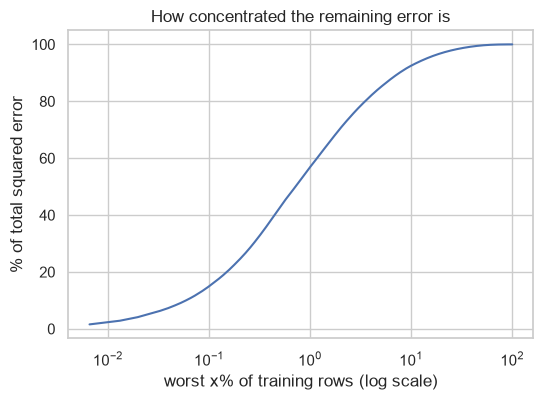

In [8]:
final_model = ridge_flight(**flight_best)
oof = evaluate.oof_predict(final_model, X, y, TASK)
err = pd.DataFrame({"flight_class": X.flight_class.values, "airline": X.airline.values,
                    "price": y.values, "pred": oof.round(0), "sq_err": (y.values - oof) ** 2})
total = err.sq_err.sum()
print("share of squared error by class:")
print((err.groupby("flight_class").sq_err.sum() / total).round(3).to_string())
print("rows per class:", err.flight_class.value_counts().to_dict())

ranked = np.sort(err.sq_err.values)[::-1]
for frac in [0.01, 0.05, 0.10]:
    print(f"worst {frac:.0%} of rows -> {ranked[:int(len(ranked) * frac)].sum() / total:.1%} of squared error")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(ranked) + 1) / len(ranked) * 100, ranked.cumsum() / total * 100)
ax.set(xscale="log", xlabel="worst x% of training rows (log scale)", ylabel="% of total squared error",
       title="How concentrated the remaining error is")
plt.savefig(FIG_DIR / "tuning_error_concentration.png", dpi=120, bbox_inches="tight")
plt.show()

- Business causes 94% of the squared error; the worst 1% of rows cause 57%.

Largest errors, and one flight that appears 17 times.

In [9]:
display(err.sort_values("sq_err", ascending=False).head(6).drop(columns="sq_err"))

same = pd.concat([X, y], axis=1).query("flight == 'EK 567' and flight_class == 'Business' and destination_city == 'Los Santos'").sort_values("days_left")
display(same[["stops", "duration", "departure_time", "arrival_time", "days_left", "price"]])

,flight_class,airline,price,pred
2530,Business,Nakatomi Airlines,317854,153429.0
8744,Business,Nakatomi Airlines,81456,231117.0
3122,Business,Stark Aviation,288886,141404.0
2847,Business,Stark Aviation,289045,143108.0
12993,Business,Stark Aviation,271552,140817.0
14604,Business,Stark Aviation,275823,147211.0


,stops,duration,departure_time,arrival_time,days_left,price
6400,one,11.42,Night,Morning,4,130960
11812,one,11.42,Night,Morning,6,130960
848,one,11.42,Night,Morning,8,130960
456,one,11.42,Night,Morning,10,130960
10454,one,11.42,Night,Morning,13,130960
8746,one,11.42,Night,Morning,14,130960
1358,one,11.42,Night,Morning,15,130960
6768,one,11.42,Night,Morning,16,155611
6790,one,11.42,Night,Morning,18,188928
414,one,11.42,Night,Morning,21,130960


- Identical features, very different prices: noise that no model can fit.

## Step 5 — Validation curves (Ridge α, tree depth)

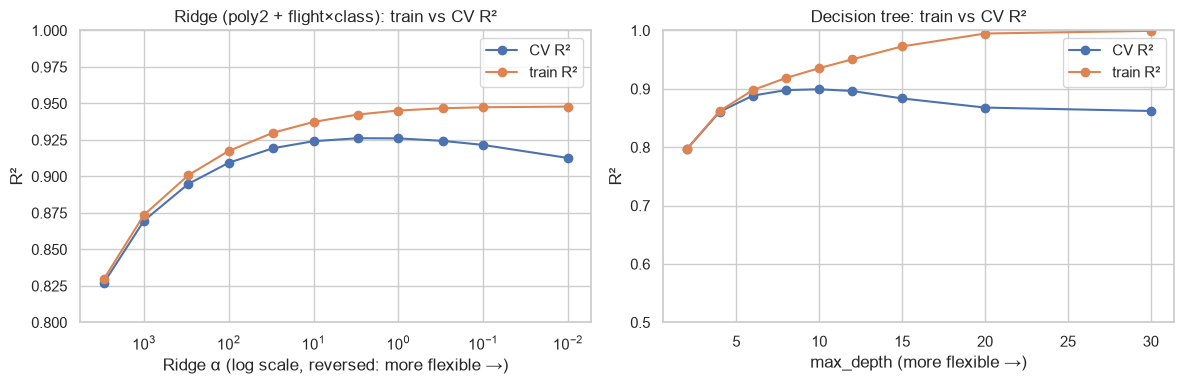

CV R²  train R²
           value                    
Ridge α    0.01     0.9127    0.9478
           0.10     0.9216    0.9474
           0.30     0.9244    0.9467
           1.00     0.9261    0.9451
           3.00     0.9262    0.9424
           10.00    0.9241    0.9373
           30.00    0.9193    0.9300
           100.00   0.9094    0.9175
           300.00   0.8949    0.9009
           1000.00  0.8697    0.8737
           3000.00  0.8268    0.8294
tree depth 2.00     0.7963    0.7964
           4.00     0.8608    0.8621
           6.00     0.8885    0.8980
           8.00     0.8979    0.9187
           10.00    0.8993    0.9355
           12.00    0.8963    0.9506
           15.00    0.8836    0.9726
           20.00    0.8679    0.9948
           30.00    0.8621    0.9993

In [10]:
def curve(make_model, values):
    rows = []
    for v in values:
        f = evaluate.cross_validate(make_model(v), X, y, TASK, "", log=False)
        rows.append({"value": v, "CV R²": f.r2.mean(), "train R²": f.train_r2.mean()})
    return pd.DataFrame(rows).set_index("value")

alpha_curve = curve(lambda a: ridge_flight(alpha=a), [0.01, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000, 3000])
depth_curve = curve(lambda d: make_pipeline(pp.make_preprocessor(scale=False),
                                            DecisionTreeRegressor(max_depth=d, random_state=config.SEED)),
                    [2, 4, 6, 8, 10, 12, 15, 20, 30])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
alpha_curve.plot(ax=axes[0], marker="o", logx=True)
axes[0].invert_xaxis()
axes[0].set(xlabel="Ridge α (log scale, reversed: more flexible →)", ylabel="R²", ylim=(0.8, 1.0),
            title="Ridge (poly2 + flight×class): train vs CV R²")
depth_curve.plot(ax=axes[1], marker="o")
axes[1].set(xlabel="max_depth (more flexible →)", ylabel="R²", ylim=(0.5, 1.0), title="Decision tree: train vs CV R²")
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_validation_curves.png", dpi=120, bbox_inches="tight")
plt.show()
display(pd.concat({"Ridge α": alpha_curve, "tree depth": depth_curve}).round(4))

- Ridge: underfits at large α, best at α 1–3, overfits at small α. Tree: CV peaks at depth 10.

## Submission

In [11]:
path, sub = evaluate.make_submission(final_model, X, y, X_test, test_ids, sample_sub, TASK, "10_ridge_flight", date="2026-10-11")
print("saved:", path.name)
print(sub["price"].describe().round(0).to_string())
print("predictions at the floor:", (sub.price == y.min()).sum())

saved: 2026-10-11_10_ridge_flight.csv
count      3898.0
mean      29757.0
std       38418.0
min        3801.0
25%        7611.0
50%       10692.0
75%       36998.0
max      278918.0
predictions at the floor: 58


- Submitted `10_ridge_flight`: public score 0.94922.